# Reproduce Fig.3 and Fig.4
This notebook illustrate how to do visualizations shown in the paper. Due to numerical optimization of GEM (from our original experiments in <span style="font-variant:small-caps;">Kaggle</span>, reproduced in <span style="font-variant:small-caps;">Github Codespace</span>), there are slight detailed variations from paper's figures, but the main claims, findings and statistical significance results remain the same.


Set up all configurations

In [1]:
## CONFIG
GH_NODES = 200
MAX_ITER = 200
MU_GAMMA = 0.1
MU_KAPPA = -0.01
KAPPA_MAX=-0.00001

OPTIMAL_KAPPA_INIT = True 

RIDGE_KAPPA = 0.1
RIDGE_GAMMA = 0.1
RIDGE_B = 0.1
RIDGE_A = 0.5
RIDGE_X0 = 1000

strict_Y_int = False

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import joblib

# Graphical configs
# 1. Reset seaborn to baseline
sns.set_style('whitegrid')
sns.set_context('paper') # Remove font_scale!

# 2. Hardcode the absolute font sizes for publication
plt.rcParams.update({
    'font.size': 9,             # Global baseline
    'figure.titlesize': 9,      # Global figure titles (Added)
    'axes.titlesize': 10,       # Title of the subplot (ax.set_title)
    'axes.labelsize': 9,        # X and Y axis labels
    'xtick.labelsize': 8,       # Numbers on the X axis
    'ytick.labelsize': 8,       # Numbers on the Y axis
    'legend.fontsize': 8,       # Legend text
    'legend.title_fontsize': 8  # Legend title
})

### Data loading

In [3]:
B_coding = pd.read_csv('data/B_coding.csv', index_col=0)
B_language = pd.read_csv('data/B_language.csv', index_col=0)
B_reasoning = pd.read_csv('data/B_reasoning.csv', index_col=0)
B_math = pd.read_csv('data/B_math.csv', index_col=0)

Y_coding = pd.read_csv('data/Y_coding.csv', index_col=0)
Y_language = pd.read_csv('data/Y_language.csv', index_col=0)
Y_reasoning = pd.read_csv('data/Y_reasoning.csv', index_col=0)
Y_math = pd.read_csv('data/Y_math.csv', index_col=0)

c_coding = pd.read_csv('data/c_coding.csv', index_col=0).set_index('question_id')
c_language = pd.read_csv('data/c_language.csv', index_col=0).set_index('question_id')
c_reasoning = pd.read_csv('data/c_reasoning.csv', index_col=0).set_index('question_id')
c_math = pd.read_csv('data/c_math.csv', index_col=0).set_index('question_id')

In [4]:
B = pd.concat([B_language, B_coding, B_reasoning, B_math],axis=0)
Y = pd.concat([Y_language, Y_coding, Y_reasoning, Y_math],axis=0)
c = pd.concat([c_language, c_coding, c_reasoning, c_math],axis=0)

In [5]:
from reasoning_aware_irt.livebench_utils import reindex
_ = reindex(Y, B, c) # little helper to make sure that all dataframes have exactly the same sorted question_id indices

the model_id Y/B sequence is great!!
the question_id Y/B sequence is great!!
the question_id Y/c sequence is great!!


In [6]:
Y_ij = Y.values
B_ij = B.values.astype(int)
c_i = c.values.squeeze()

print(Y_ij.shape, B_ij.shape)
print(Y_ij.mean(), B_ij.mean())
print(c_i.shape, c_i[:5])

(786, 42) (786, 42)
0.39359059581389527 1310.9940930570701
(786,) [1.e-05 1.e-05 1.e-02 1.e-02 1.e-02]


In [7]:
model_list = np.array(list(B.columns)) 
print(model_list.shape, model_list[-5:])

(42,) ['baidu/ernie-4.5-21b-a3b-thinking' 'allenai/olmo-3-7b-think'
 'qwen/qwen3-30b-a3b-thinking-2507' 'google/gemma-3-27b-it:free'
 'meta-llama/llama-4-scout']


### load results from multi-pass GEM (see  `fig2_posthoc.ipynb`)

In [8]:
fit_results = joblib.load('data/fit_results_3rd_pass.pkl')

In [9]:
from reasoning_aware_irt.utils import plot_parameter_scatter_with_se
from reasoning_aware_irt.gem_quad import CalibrationData, compute_louis_se
from reasoning_aware_irt.posthoc import extract_slice_data

In [ ]:
data = CalibrationData(Y_ij=Y_ij, B_ij=B_ij, c_i=c_i)
out = compute_louis_se(result=fit_results, data=data) # Section 3.4 and Appendix A

/workspaces/reasoning-aware-irt/reasoning_aware_irt/utils.py:488: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


Text(1, 0, 'b_i')

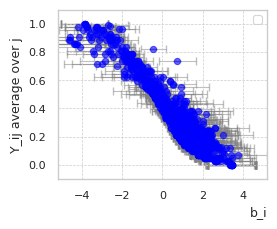

In [11]:
fig, axs = plt.subplots(1, 1, figsize=(2.7, 2.2))

# Fig 3 (top-left)
plot_parameter_scatter_with_se(axs, fit_results.b_i, Y_ij.mean(axis=1),   
                               out['b_se_louis'].clip(0,2), 
                               min_xlim=-5.2, max_xlim=5.2,
                               min_ylim=-0.1, max_ylim=1.1,
                               x_label="b_i", y_label=f"Y_ij average over j",
                               # y_label=r"$\bar{Y}_{i,:}$",
                               title="",
                               plot_ref_line=False,
                              ) # fitted  b_i values
plt.xlabel('b_i', loc='right') 
# plt.savefig("fig3_top_left.pdf", format='pdf', bbox_inches='tight', dpi=300, pad_inches=0.0, transparent=True)

Note that we explain the two visible outliers in the above figure in Appendix C.

In [12]:
from reasoning_aware_irt.utils import plot_binned_with_quad_fit, plot_combined_binned_data

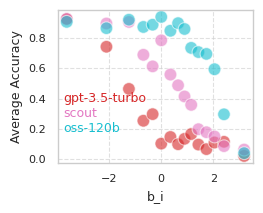

In [13]:
ds_overlaid_list = []

for j in [24,41,35]:
    ds = {
    'x': fit_results.b_i,
    'y': Y_ij[:, j],
    'title': f'{model_list[j]}',
    'plot_function': plot_binned_with_quad_fit,
    'plot_function_argv' : {
        'num_bins': 15,
        'return_best_bin':True,
        'best_bin_thresh':30, 
        'min_points_per_bin':3, 
        'use_quantiles':True,
        'plot_quad': False,
        'x_label':"b_i",
        'y_label':"Average Y",
        'display_legend':False,
        "size_norm":0.2,
        "alpha":0.5,
        "show_count":False
        }
    }
    ds_overlaid_list.append(ds)
ds_overlaid_list[0]['nickname'] = 'gpt-3.5-turbo'
ds_overlaid_list[1]['nickname'] = 'scout'
ds_overlaid_list[2]['nickname'] = 'oss-120b'

_ = plot_combined_binned_data(ds_overlaid_list, show_legend=False,
                              # save_path="overlaid_b_vs_Y.pdf", figsize=(7,3),
                              save_path=None, figsize=(2.7,2.2),
                              xlabel="b_i", ylabel="Average Accuracy", title="",nickname=True)

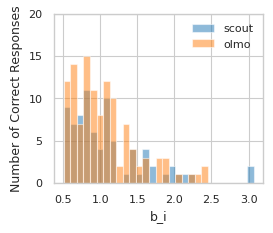

In [14]:
id1, id2 = 41, 38 # scout vs. olmo

THRESH=0.75 # threshold of score to be counted
THRESH_B = 0.5 # for plot to focus only on more difficult questions

 # find b's indices which the model success then histogram
id_b1 = np.where(np.logical_and(Y_ij[:, id1] > THRESH, fit_results.b_i>THRESH_B))[0]
id_b2 = np.where(np.logical_and(Y_ij[:, id2] > THRESH, fit_results.b_i>THRESH_B))[0]

df1 = pd.DataFrame({f"{model_list[id1]}" : fit_results.b_i[id_b1]})
df2 = pd.DataFrame({f"{model_list[id2]}" : fit_results.b_i[id_b2]})

min_val = min(df1.values.min(), df2.values.min())
max_val = max(df1.values.max(), df2.values.max())
bins = np.linspace(min_val, max_val, 30)

figsize=(2.7, 2.2)
# use nickname for legend
ax = df1.plot.hist(bins=bins, alpha=0.5, label='olmo',#f'{model_list[id1]}',
                   legend='olmo',
                   ylim=(0,20),figsize=figsize )
ax = df2.plot.hist(bins=bins, alpha=0.5, label=f'{model_list[id2]}',
                   ylim=(0,20), ax=ax,
                   legend=f"scout", 
                   figsize=figsize)

# ax.set_title("Distribution of Scores")
ax.set_xlabel("b_i")
ax.set_ylabel("Number of Correct Responses")
ax.legend(['scout', 'olmo'], frameon=False)

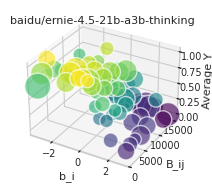

In [18]:
from reasoning_aware_irt.utils import plot_bins_2d
model_id = 37
_ = plot_bins_2d(np.vstack([fit_results.b_i, B_ij[:,model_id]]).T, 
                 Y_ij[:, model_id], 
                 num_bins=8, min_points_per_bin=2, use_quantiles=True, show_count=False,title=f'{model_list[model_id]}',title_pad=0,
                 ax=None, fig=None, row=None, col=None, use_plotly=False, return_best_bin=False, 
                 x1_label="b_i", x2_label="B_ij", z_label="Average Y", alpha=0.65,show_colorbar=False,
                 label="", cmap='viridis', figsize=(2.7, 2.2), save_path=None, box_aspect=(1.1, 1, 0.8))

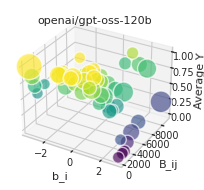

In [19]:
model_id = 35
_ = plot_bins_2d(np.vstack([fit_results.b_i, B_ij[:,model_id]]).T, 
                 Y_ij[:, model_id], 
                 num_bins=8, min_points_per_bin=2, use_quantiles=True, show_count=False,title=f'{model_list[model_id]}',title_pad=0,
                 ax=None, fig=None, row=None, col=None, use_plotly=False, return_best_bin=False, 
                 x1_label="b_i", x2_label="B_ij", z_label="Average Y", alpha=0.65,show_colorbar=False,
                 label="", cmap='viridis', figsize=(2.7, 2.2), save_path=None, box_aspect=(1.1, 1, 0.8))

### Fig. 4(a)
Below we show how to extract $b_i$-*conditioned* plots on **oss-120b-hard**, **oss-120b-easy** and **ernie-hard**, without paper space constraints, here we take an opportunity to layout more details. Number of each dot denotes *the number of data* on that bin.

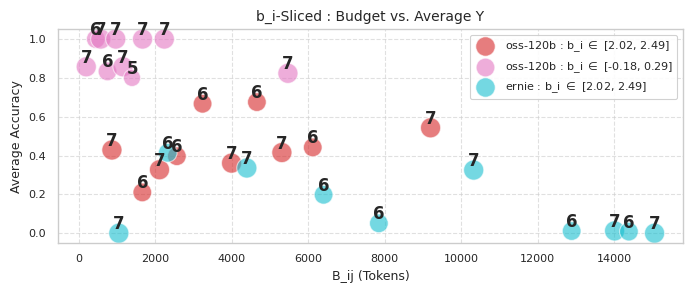

In [16]:
# Fig 4(a) with more details

# 1. Extract the raw 1D arrays for the specific slices (partitions)
# we partition (Y, B_ij) on various level of b_i , the so called b_i-conditioned in the paper
oss_120b_easy_slice_idx = 4 # early partition --> easy problems
oss_120b_hard_slice_idx = 10 # late partition --> difficult problems
ernie_overthink_slice_idx = 10 # late partition --> difficult problems

x_a, y_a, title_a = extract_slice_data( np.vstack([fit_results.b_i, B_ij[:,35]]).T,
                                       Y_ij[:,35], use_quantiles=True,
                                       slice_axis=0, num_slices=12, 
                                       target_slice_idx=oss_120b_easy_slice_idx, 
                                       slice_label=f"oss-120b : b_i")
x_b, y_b, title_b = extract_slice_data(np.vstack([fit_results.b_i, B_ij[:,35]]).T,
                                       Y_ij[:,35], use_quantiles=True,
                                       slice_axis=0, num_slices=12, 
                                       target_slice_idx=oss_120b_hard_slice_idx, 
                                       slice_label=f"oss-120b : b_i")
x_c, y_c, title_c = extract_slice_data(np.vstack([fit_results.b_i, B_ij[:,37]]).T,
                                       Y_ij[:,37], use_quantiles=True,
                                       slice_axis=0, num_slices=12, 
                                       target_slice_idx=ernie_overthink_slice_idx, 
                                       slice_label=f"ernie : b_i")


x_list, y_list, title_list = [x_b, x_a, x_c], [y_b, y_a, y_c], [title_b, title_a, title_c]

# 2. Package them into the format expected by your wrapper
datasets_to_plot = []
for i in range(3):
    datasets_to_plot.append({
        "x": x_list[i], "y": y_list[i], 
        "title": title_list[i],             # E.g., "model_name's b_i \in [1.50, 2.10]"
        "plot_function": plot_binned_with_quad_fit,   # Use the 1D plotting function
        "plot_function_argv": {
            "num_bins": 10,
            'use_quantiles':True,
            "min_points_per_bin": 3,
            "size_norm":0.5,
            "alpha":0.5
            }
        } )
# 3. Plot them together!
_ = plot_combined_binned_data(
    datasets_to_plot, 
    xlabel="B_ij (Tokens)",
    ylabel="Average Accuracy", 
    title="b_i-Sliced : Budget vs. Average Y",
    save_path=None, #"overlaid_slice_B_vs_Y.pdf",
    figsize=(7,3)
)